# Experimental Setup & Statistical Verification

**Compositional Image Retrieval on CelebA — Deep Learning Assignment 2026**

This notebook is the statistical evaluation of our compositional-retrieval architectures against the
enhanced Tier-0 baseline, on the official 13-query CelebA benchmark
(`Evaluation/celeba_evaluation.json`). It goes beyond single-point metric reporting: every number is
accompanied by a bootstrap confidence interval, every comparison by a paired significance test, and
every claim about *compositional* robustness by a per-category breakdown and a qualitative analysis of
the hard negation queries.

**Models under comparison** (display name ← checkpoint/run)

| Display name | Model | Type | Seeds |
|---|---|---|---|
| **CLIP** | `tier0_CLIP` — vanilla latent arithmetic, unmodified CLIP | training-free | deterministic |
| **CLIP Enhanced** | `tier0_enhanced_all_fixes` — latent arithmetic with correct CLIP geometry | training-free | deterministic |
| **CLAY** | `tier1_CLAY_k50_rotH` — CLAY reproduction (k=50, rotation) | training-free | deterministic |
| **DGP** | `tier2d_tau100.0_a1.0_center` — gated projection, uniform gate, centered | training-free | deterministic |
| **Dual Score** | `tier3_dualscore` — query-conditioned dual-channel fusion (ListNet) | learned | 0, 1, 2 |
| **Bayes** | `tier5_Bprime_listnet_seed0` — CD-Bayes + learned Φ (ListNet) — **champion** | learned | 0 (seeds 1–2 pending) |

Bayes is the champion (R@1 = 0.1104, R@5 = 0.2913, R@10 = 0.4128). Its LambdaLoss sibling — *designed*
to improve R@1 — underperformed the ListNet control on **all three seeds**; it is kept out of the main
figures but analyzed in §B.1 as a faithfully reported negative result and as the empirical evidence for
the size of training-seed variance in this architecture.


## Section A — Statistical Framework & Methodology

### A.1 Metrics: spec-locked by design

The assignment specification (§3.1.3) mandates exactly two metrics, evaluated at $K \in \{1, 5, 10\}$
and averaged over all valid source images of each query:

$$\mathrm{Recall@}K(s) \;=\; \mathbb{1}\!\left[\, |R_K(s) \cap G(s)| > 0 \,\right], \qquad
\mathrm{Precision@}K(s) \;=\; \frac{|R_K(s) \cap G(s)|}{K},$$

where $R_K(s)$ is the top-$K$ retrieved set for source $s$ and $G(s)$ its ground-truth set. We report
**only** these. Adding non-mandated metrics (MRR, NDCG, …) would dilute comparability with the official
benchmark and invite metric shopping; and it is unnecessary — the per-source outcomes
$\mathrm{hit@}K(s) \in \{0,1\}$ and $\mathrm{Precision@}K(s) \in [0,1]$ are well-defined random
variables over the fixed source population, which is exactly the raw material resampling inference
needs. Everything below is a *statistic about* the two spec metrics, never a new metric.

### A.2 Why single-run point estimates are insufficient

A single macro-mean (the `MEAN` row of a results CSV) is a point estimate of
$\theta = \frac{1}{Q}\sum_{q=1}^{Q} \mathbb{E}_s[\,m_q(s)\,]$ computed from finitely many sources
(here $n_q \in [27, 5469]$ per query). Two models whose means differ by less than the sampling noise of
that estimate cannot honestly be ranked. We therefore attach an uncertainty statement to every mean and
a significance statement to every comparison.

### A.3 Stratified bootstrap confidence intervals

The 13 benchmark queries are a **fixed benchmark**, not a random sample from a query population
(spec §3.1 prescribes them exhaustively). The random unit is the *source image* within each query. The
correct resampling scheme is therefore **stratified**: queries are strata and are never resampled;
sources are resampled with replacement within their query. For $b = 1, \dots, B$ ($B = 1000$):

$$\hat\theta^{*}_{b} \;=\; \frac{1}{Q} \sum_{q=1}^{Q} \frac{1}{n_q} \sum_{i=1}^{n_q} m_q\!\big(s^{*}_{q,i,b}\big),
\qquad s^{*}_{q,i,b} \sim \mathrm{Uniform}\{s_{q,1}, \dots, s_{q,n_q}\},$$

which is precisely the statistic of the published `MEAN` row, recomputed on each replicate. The 95% CI
is the percentile interval $[\hat\theta^{*}_{(0.025)}, \hat\theta^{*}_{(0.975)}]$. (A BCa refinement is
possible but changes nothing at $n_q$ in the hundreds-to-thousands; the percentile interval is adequate
and simpler to audit.)

### A.4 Significance: paired bootstrap — and why *not* a rank test

Per-source $\mathrm{hit@}K$ is **binary**. The Wilcoxon signed-rank test — the usual nonparametric
choice — is ill-posed on paired Bernoulli differences: all zero-differences are discarded, the
remaining differences are massively tied at $\pm 1$, and the tested quantity (a median of differences)
is degenerate. We instead use the **paired stratified bootstrap of the difference**. Both models are
evaluated on the *identical* source population (same ground-truth JSON), so for each replicate we apply
the **same** resampled indices to both models and compute

$$\Delta^{*}_{b} \;=\; \hat\theta^{*}_{A,b} - \hat\theta^{*}_{B,b}.$$

Sharing indices removes between-source variance from $\Delta$ — the pairing that gives the test its
power. We report the 95% CI of $\Delta$, the relative gain $\Delta / \hat\theta_B$, and the two-sided
bootstrap p-value with small-sample correction

$$p \;=\; 2\min\!\left( \frac{\#\{\Delta^{*}_{b} \le 0\} + 1}{B+1},\; \frac{\#\{\Delta^{*}_{b} \ge 0\} + 1}{B+1} \right).$$

A difference is significant at $\alpha = 0.05$ iff the CI excludes 0 — by construction the CI and the
p-value cannot contradict each other. Because we test multiple metrics and multiple baselines, all
p-values are **Holm–Bonferroni corrected**. The correction family is the $\{6 \text{ metrics} \times
5 \text{ baselines}\}$ comparisons *of one model*: training seeds are not additional hypotheses — they
are replicates of the same hypothesis, and their multiplicity is handled by the stricter worst-seed
criterion of §A.5 (all seeds must individually pass), not by inflating the Holm family.

One resolution requirement follows from the correction: the bootstrap p-value cannot fall below
$2/(B+1)$, so with a Holm family of $m = 30$ tests the significance runs use $B = 10{,}000$
($30 \cdot 2/10{,}001 \approx 0.006 < 0.05$) — otherwise finite resolution, not evidence, would
mask real effects. CIs keep $B = 1000$, ample for percentile endpoints.

### A.5 Two sources of randomness — the multi-seed protocol

Trained models carry a second, independent source of variance: the training seed (initialization, data
ordering, stochastic query sampling). Bootstrap over sources cannot see it. Our protocol:

* **Training-free tiers (0, 2d, 5-A′) are deterministic** — zero seed variance, a stated methodological strength.
* **Learned models are trained $n \ge 3$ times** where budget permits and reported as mean ± std across
  seeds. The LambdaLoss family has the full 3 seeds; the ListNet champion currently has **one** seed —
  an explicitly stated limitation (seeds 1–2 are queued on the VM:
  `python src/tier5_cdbayes.py --rows Bprime_listnet --full-seeds`), partially mitigated by the fact
  that its margin over the baselines exceeds the *entire* seed spread observed in the sibling
  LambdaLoss family trained under the identical protocol.
* Seeds are **never pooled as data points** ($n=3$ is far too small for any test). Instead, the paired
  bootstrap test is run **per seed**, and we claim significance only if it holds for **every** seed —
  the conservative *worst-seed criterion* (applied in full to the multi-seed family; for the champion
  it degenerates to its single seed until the remaining runs land).

### A.6 Robustness to negation and hard compositional queries

The benchmark queries are stratified into a taxonomy that follows the spec's own complexity levels,
with the project's target case split out:

* **simple positive** (`+Smiling`, …), **simple negative** (`-Young`, …),
* **composed** (mixed polarity, e.g. `+Chubby, -Young`),
* **pure negation** (`-Male, -Mustache`) — the hard case: no positive constraint anchors the query.

We report the macro metrics per category, so a model cannot hide a negation failure inside a good
average. One contextual fact matters for reading the pure-negation row: `-Male, -Mustache` is largely
an *identity-retrieval* problem across a gender cluster boundary — an oracle upper bound using
ground-truth attribute labels with CLIP cosine identity reaches only $R@10 \approx 0.074$ on it, so
absolute scores on this query are ceiling-limited for every CLIP ViT-B/32 method.


In [1]:
# Setup — thin cells only: all statistics live in src/stats_eval.py, dumps in src/per_source.py.
import sys
from pathlib import Path

import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if (Path.cwd() / "..").resolve().name == "Deep-Learning-Project" else Path.cwd()
ROOT = ROOT if (ROOT / "src").exists() else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from eval import find_eval_json, load_eval_json
from per_source import load_per_source, per_source_dir
from stats_eval import (category_breakdown, holm_bonferroni, macro_vs_micro, metric_label,
                        paired_bootstrap_diff, plot_bootstrap_violin, plot_ci_bars,
                        recall_curve, stratified_bootstrap, win_tie_loss)

B = 1000          # bootstrap replicates for CIs (§A.3)
B_SIG = 10_000    # replicates for significance tests — the bootstrap p-value floor is
                  # 2/(B+1), and the Holm family is 30 tests, so B must satisfy
                  # 30 · 2/(B+1) < 0.05 for resolution not to mask real effects (§A.4)
SEEDS = (0, 1, 2) # multi-seed protocol (§A.5)
GT_LIST = load_eval_json(find_eval_json())

MODELS = {  # display name -> per-source dump file (names used in every figure/table)
    "CLIP":          "tier0_CLIP_baseline.npz",
    "CLIP Enhanced": "tier0_enhanced_all_fixes.npz",
    "CLAY":          "tier1_CLAY_k50_rotH.npz",
    "DGP":           "tier2d_tau100.0_a1.0_center.npz",
    "Dual Score":    "tier3_dualscore.npz",
    "Bayes":         "tier5_Bprime_listnet_seed0.npz",
}
# Ablation-only dumps (§A.5 seed-variance evidence; excluded from the main figures).
ABLATION = {f"Bayes-LambdaLoss seed{s}": f"tier5_Bprime_lambdaloss_seed{s}.npz" for s in SEEDS}


def _load_available(mapping):
    out = {}
    for name, fname in mapping.items():
        path = per_source_dir() / fname
        if path.exists():
            out[name] = load_per_source(path)
        else:
            print(f"[missing] {fname} — run the corresponding --dump-per-source command "
                  f"(see scripts/) and re-execute; '{name}' is skipped below.")
    return out


dumps = _load_available(MODELS)
ablation_dumps = _load_available(ABLATION)
print(f"Loaded per-source dumps: {list(dumps)}  (+{len(ablation_dumps)} ablation)")

Loaded per-source dumps: ['CLIP', 'CLIP Enhanced', 'CLAY', 'DGP', 'Dual Score', 'Bayes']  (+3 ablation)


## Section B — Executable Statistical Suite

### B.1 Bootstrap confidence intervals (all models, all spec metrics)

Each cell below is intentionally thin: the statistical logic lives in
[`src/stats_eval.py`](../src/stats_eval.py), unit-tested in `test/test_stats_eval.py`, and the raw
per-source outcomes in parity-gated dumps (`src/per_source.py` — each dump is verified to reproduce its
published CSV row-for-row before it is written).

In [2]:
# Point estimate, bootstrap mean±std, and percentile 95% CI for every model × metric (§A.3).
boot = {name: stratified_bootstrap(d, B=B, seed=0) for name, d in dumps.items()}

rows = []
for name, res in boot.items():
    row = {"model": name}
    for f, r in res.items():
        row[metric_label(f)] = f"{r.point:.4f} ± {r.std:.4f}  [{r.ci_lo:.4f}, {r.ci_hi:.4f}]"
    rows.append(row)
ci_table = pd.DataFrame(rows).set_index("model")
ci_table

,R@1,R@5,R@10,P@1,P@5,P@10
model,,,,,,
CLIP,"0.0224 ± 0.0026 [0.0182, 0.0277]","0.0699 ± 0.0043 [0.0630, 0.0790]","0.1048 ± 0.0049 [0.0964, 0.1147]","0.0224 ± 0.0026 [0.0182, 0.0277]","0.0172 ± 0.0010 [0.0155, 0.0192]","0.0141 ± 0.0006 [0.0130, 0.0153]"
CLIP Enhanced,"0.0397 ± 0.0038 [0.0331, 0.0480]","0.1140 ± 0.0057 [0.1042, 0.1256]","0.1651 ± 0.0061 [0.1543, 0.1776]","0.0397 ± 0.0038 [0.0331, 0.0480]","0.0272 ± 0.0012 [0.0249, 0.0297]","0.0225 ± 0.0008 [0.0212, 0.0241]"
CLAY,"0.0098 ± 0.0010 [0.0081, 0.0119]","0.0368 ± 0.0036 [0.0307, 0.0445]","0.0541 ± 0.0037 [0.0476, 0.0618]","0.0098 ± 0.0010 [0.0081, 0.0119]","0.0086 ± 0.0008 [0.0073, 0.0102]","0.0070 ± 0.0004 [0.0063, 0.0080]"
DGP,"0.0363 ± 0.0027 [0.0312, 0.0416]","0.1152 ± 0.0053 [0.1055, 0.1261]","0.1777 ± 0.0063 [0.1656, 0.1903]","0.0363 ± 0.0027 [0.0312, 0.0416]","0.0285 ± 0.0013 [0.0260, 0.0312]","0.0248 ± 0.0010 [0.0230, 0.0267]"
Dual Score,"0.0597 ± 0.0043 [0.0517, 0.0686]","0.1749 ± 0.0061 [0.1635, 0.1876]","0.2557 ± 0.0066 [0.2428, 0.2690]","0.0597 ± 0.0043 [0.0517, 0.0686]","0.0485 ± 0.0020 [0.0447, 0.0526]","0.0408 ± 0.0014 [0.0382, 0.0435]"
Bayes,"0.1104 ± 0.0061 [0.0998, 0.1226]","0.2913 ± 0.0082 [0.2758, 0.3080]","0.4128 ± 0.0091 [0.3942, 0.4310]","0.1104 ± 0.0061 [0.0998, 0.1226]","0.0811 ± 0.0026 [0.0763, 0.0865]","0.0722 ± 0.0017 [0.0688, 0.0758]"


In [3]:
# Seed variance (§A.5): mean ± std ACROSS seeds (training variance), reported separately
# from the per-seed bootstrap CI (test-set variance) — never conflated. Evidence comes
# from the Bayes-LambdaLoss ablation family (3 seeds, identical training protocol).
if ablation_dumps:
    fam = {n: stratified_bootstrap(d, B=B, seed=0) for n, d in ablation_dumps.items()}
    print(f"Bayes-LambdaLoss ablation family: n={len(fam)} seeds")
    for f in ("hit1", "hit5", "hit10"):
        pts = np.array([r[f].point for r in fam.values()])
        print(f"  {metric_label(f)}: across-seed mean={pts.mean():.4f}  std={pts.std(ddof=1):.4f}")
print("Bayes (champion): n=1 seed — across-seed std unavailable; see §A.5 limitation. "
      "The LambdaLoss family above bounds the expected seed spread under the identical protocol.")

Bayes-LambdaLoss ablation family: n=3 seeds
  R@1: across-seed mean=0.0738  std=0.0079
  R@5: across-seed mean=0.2217  std=0.0181
  R@10: across-seed mean=0.3315  std=0.0163
Bayes (champion): n=1 seed — across-seed std unavailable; see §A.5 limitation. The LambdaLoss family above bounds the expected seed spread under the identical protocol.


### B.2 Significance: Bayes vs every baseline (paired bootstrap, worst-seed criterion)

In [4]:
# Paired bootstrap Δ with 95% CI + Holm-corrected p (§A.4). The champion (Bayes) and the
# multi-seed LambdaLoss ablation family are each tested against every available baseline;
# the worst-seed criterion (§A.5) is evaluated over whichever seeds exist per family.
CHAMPIONS = (["Bayes"] if "Bayes" in dumps else []) + list(ablation_dumps)
BASELINES = [n for n in ("CLIP", "CLIP Enhanced", "CLAY", "DGP", "Dual Score") if n in dumps]
test_dumps = {**dumps, **ablation_dumps}

diff_rows, adj = [], {}
for champ in CHAMPIONS:
    # Holm family = the {metrics × baselines} comparisons of THIS model (§A.4): seeds are
    # replicates of one hypothesis (handled by the worst-seed criterion), not extra tests.
    family_p = {}
    for base in BASELINES:
        diffs = paired_bootstrap_diff(test_dumps[champ], dumps[base], B=B_SIG, seed=0)
        for f, r in diffs.items():
            family_p[f"{champ} vs {base} | {metric_label(f)}"] = r.p_value
            diff_rows.append({"comparison": f"{champ} vs {base}", "metric": metric_label(f),
                              "delta": r.delta, "rel_gain_%": 100 * r.rel_gain,
                              "CI95": f"[{r.ci_lo:.4f}, {r.ci_hi:.4f}]", "p_raw": r.p_value})
    adj.update(holm_bonferroni(family_p))

diff_table = pd.DataFrame(diff_rows)
diff_table["p_holm"] = [adj[f"{r.comparison} | {r.metric}"] for r in diff_table.itertuples()]
diff_table["significant"] = diff_table["p_holm"] < 0.05
diff_table.round(4)

,comparison,metric,delta,rel_gain_%,CI95,p_raw,p_holm,significant
0,Bayes vs CLIP,R@1,0.0880,393.1254,"[0.0754, 0.1013]",0.0002,0.0060,True
1,Bayes vs CLIP,R@5,0.2214,316.6062,"[0.2040, 0.2394]",0.0002,0.0060,True
2,Bayes vs CLIP,R@10,0.3079,293.7814,"[0.2884, 0.3276]",0.0002,0.0060,True
3,Bayes vs CLIP,P@1,0.0880,393.1254,"[0.0754, 0.1013]",0.0002,0.0060,True
4,Bayes vs CLIP,P@5,0.0638,369.9967,"[0.0590, 0.0694]",0.0002,0.0060,True
...,...,...,...,...,...,...,...,...
115,Bayes-LambdaLoss seed2 vs Dual Score,R@5,0.0300,17.1393,"[0.0127, 0.0478]",0.0010,0.0060,True
116,Bayes-LambdaLoss seed2 vs Dual Score,R@10,0.0587,22.9670,"[0.0378, 0.0799]",0.0002,0.0060,True
117,Bayes-LambdaLoss seed2 vs Dual Score,P@1,0.0056,9.4598,"[-0.0063, 0.0180]",0.3538,0.7075,False
118,Bayes-LambdaLoss seed2 vs Dual Score,P@5,0.0059,12.2091,"[0.0013, 0.0106]",0.0108,0.0324,True


In [5]:
# Worst-seed verdict (§A.5): a claim stands only if it holds for EVERY trained seed.
# The Bayes champion is n=1 seed (flagged); LambdaLoss applies the full 3-seed criterion.
for fam, label in (("Bayes vs", "Bayes champion (n=1 seed)"),
                   ("Bayes-LambdaLoss seed", "LambdaLoss ablation family")):
    for base in BASELINES:
        for metric in ("R@1", "R@5", "R@10"):
            sub = diff_table[(diff_table.metric == metric)
                             & diff_table.comparison.str.endswith(f"vs {base}")
                             & diff_table.comparison.str.startswith(fam)]
            if len(sub):
                verdict = "SIGNIFICANT (all seeds)" if sub.significant.all() else \
                          f"NOT robust ({int(sub.significant.sum())}/{len(sub)} seeds pass)"
                print(f"{label:<28s} vs {base:<16s} {metric:<5s} "
                      f"min Δ={sub.delta.min():+.4f}  -> {verdict}")

Bayes champion (n=1 seed)    vs CLIP             R@1   min Δ=+0.0880  -> SIGNIFICANT (all seeds)
Bayes champion (n=1 seed)    vs CLIP             R@5   min Δ=+0.2214  -> SIGNIFICANT (all seeds)
Bayes champion (n=1 seed)    vs CLIP             R@10  min Δ=+0.3079  -> SIGNIFICANT (all seeds)
Bayes champion (n=1 seed)    vs CLIP Enhanced    R@1   min Δ=+0.0706  -> SIGNIFICANT (all seeds)
Bayes champion (n=1 seed)    vs CLIP Enhanced    R@5   min Δ=+0.1773  -> SIGNIFICANT (all seeds)
Bayes champion (n=1 seed)    vs CLIP Enhanced    R@10  min Δ=+0.2477  -> SIGNIFICANT (all seeds)
Bayes champion (n=1 seed)    vs CLAY             R@1   min Δ=+0.1005  -> SIGNIFICANT (all seeds)
Bayes champion (n=1 seed)    vs CLAY             R@5   min Δ=+0.2545  -> SIGNIFICANT (all seeds)
Bayes champion (n=1 seed)    vs CLAY             R@10  min Δ=+0.3587  -> SIGNIFICANT (all seeds)
Bayes champion (n=1 seed)    vs DGP              R@1   min Δ=+0.0741  -> SIGNIFICANT (all seeds)
Bayes champion (n=1 seed)    v

### B.3 Headline figures — CI bar chart and bootstrap distributions

In [6]:
out_dir = ROOT / "output" / "visual"
out_dir.mkdir(exist_ok=True)
fig = plot_ci_bars(boot, path=out_dir / "stats_ci_bars.png")
fig

<Figure size 900x500 with 1 Axes>

In [7]:
# Bootstrap distributions: separated violins are a visual significance statement (§A.4).
fig = plot_bootstrap_violin(boot, field="hit1", path=out_dir / "stats_violin_r1.png")
fig

<Figure size 900x500 with 1 Axes>

In [8]:
fig = plot_bootstrap_violin(boot, field="hit10", path=out_dir / "stats_violin_r10.png")
fig

<Figure size 900x500 with 1 Axes>

### B.4 Compositional robustness — per-category breakdown (§A.6)

In [9]:
cat_rows = []
for name, d in dumps.items():
    for cat, metrics in category_breakdown(d).items():
        cat_rows.append({"model": name, "category": cat, **metrics})
cat_table = pd.DataFrame(cat_rows).pivot_table(index="model", columns="category", values="R@10")
cat_table.round(4)

category,composed,pure negation,simple negative,simple positive
model,,,,
Bayes,0.4721,0.4444,0.2504,0.4121
CLAY,0.0272,0.0000,0.0696,0.0856
CLIP,0.0851,0.0000,0.0952,0.1493
CLIP Enhanced,0.1529,0.0000,0.1009,0.2360
DGP,0.1887,0.0000,0.0895,0.2374
Dual Score,0.3170,0.0370,0.1307,0.2882


In [10]:
import matplotlib.pyplot as plt

### B.5 Where does the gain come from? Win/tie/loss and paired contingency

In [11]:
# Per query: on how many of the 13 queries does the champion beat the baseline?
# Per source (K=10): both hit / only champion / only baseline / neither — shows whether the
# champion FIXES baseline failures or merely trades sources.
champ = CHAMPIONS[0]
for base in BASELINES:
    wtl = win_tie_loss(test_dumps[champ], dumps[base], k=10)
    print(f"{champ} vs {base}")
    print(f"  per-query  W/T/L = {wtl['per_query']['win']}/{wtl['per_query']['tie']}/{wtl['per_query']['loss']}")
    c = wtl["per_source@k"]
    n = sum(c.values())
    print(f"  per-source @10: both {c['both']} | only champion {c['only_a']} | "
          f"only baseline {c['only_b']} | neither {c['neither']}   (n={n})")

Bayes vs CLIP
  per-query  W/T/L = 12/0/1
  per-source @10: both 1908 | only champion 7542 | only baseline 1782 | neither 16465   (n=27697)
Bayes vs CLIP Enhanced
  per-query  W/T/L = 12/0/1
  per-source @10: both 2651 | only champion 6799 | only baseline 2370 | neither 15877   (n=27697)
Bayes vs CLAY
  per-query  W/T/L = 12/0/1
  per-source @10: both 1053 | only champion 8397 | only baseline 847 | neither 17400   (n=27697)
Bayes vs DGP
  per-query  W/T/L = 12/0/1
  per-source @10: both 2641 | only champion 6809 | only baseline 2184 | neither 16063   (n=27697)
Bayes vs Dual Score
  per-query  W/T/L = 11/0/2
  per-source @10: both 3543 | only champion 5907 | only baseline 2633 | neither 15614   (n=27697)


### B.6 Robustness to the averaging convention, and the full recall curve

In [12]:
# Macro (each query 1/13 — spec convention) vs micro (each source equal): num_sources spans
# 27…5469, so agreement here proves the headline number isn't an averaging artifact.
mm_rows = []
for name, d in dumps.items():
    mm = macro_vs_micro(d)
    mm_rows.append({"model": name,
                    "R@10 macro": mm["macro"]["R@10"], "R@10 micro": mm["micro"]["R@10"],
                    "R@5 macro": mm["macro"]["R@5"], "R@5 micro": mm["micro"]["R@5"]})
pd.DataFrame(mm_rows).set_index("model").round(4)

,R@10 macro,R@10 micro,R@5 macro,R@5 micro
model,,,,
CLIP,0.1048,0.1332,0.0699,0.0837
CLIP Enhanced,0.1651,0.1813,0.1140,0.1211
CLAY,0.0541,0.0686,0.0368,0.0434
DGP,0.1777,0.1742,0.1152,0.1143
Dual Score,0.2557,0.2230,0.1749,0.1490
Bayes,0.4128,0.3412,0.2913,0.2281


In [13]:
# Recall@K for EVERY K = 1…10 (from the stored top-10 prefixes) — locates where in the
# ranking the gain materializes.
fig, ax = plt.subplots(figsize=(7, 4.5))
for name, d in dumps.items():
    ax.plot(range(1, 11), recall_curve(d, GT_LIST), marker="o", ms=3, label=name)
ax.set_xlabel("K"), ax.set_ylabel("macro Recall@K"), ax.legend(fontsize=7)
ax.set_title("Recall@K, K = 1…10")
fig.tight_layout()
fig.savefig(out_dir / "stats_recall_curve.png", dpi=120)
fig

<Figure size 700x450 with 1 Axes>

### B.7 Full tier comparison (published CSVs) and model cost

The statistical suite above covers the champions. For completeness, the table below tabulates every
published tier/ablation CSV (macro `MEAN` rows) — including the *failed* ablation variants, reported
honestly: Tier-2's sharp gate (τ=0.07) underperforms its own uniform-gate variant, and Tier-2c's
visual-subspace negation was a negative result that motivated the probabilistic turn of Tiers 4/5.

In [14]:
import csv as _csv

def mean_row(path):
    with open(path, newline="", encoding="utf-8") as f:
        for r in _csv.DictReader(f):
            if r["query"] == "MEAN":
                return {k: float(v) for k, v in r.items() if k not in ("query", "num_sources") and v}
    return None

CSVS = {  # representative rows: the report roster plus the noted failed ablations
    "CLIP":                      "tier0_CLIP/tier0_baseline.csv",
    "CLIP Enhanced":             "tier0_enhanced/tier0_enhanced_all_fixes.csv",
    "CLAY":                      "tier1_CLAY/tier1_CLAY_k50_rotH.csv",
    "DGP sharp gate (failed)":   "tier2d/tier2d_tau0.07_a1.0_center.csv",
    "DGP":                       "tier2d/tier2d_tau100.0_a1.0_center.csv",
    "Dual Score":                "tier3_dualscore/tier3_dualscore.csv",
    "Tier3 symneg (ablation)":   "tier3_symneg/tier3_symneg_k50_tau0.07_a1.csv",
    "Bayes A' core (train-free)": "tier5_cdbayes/tier5_Aprime_C4C5_full.csv",
    "Bayes (champion)":          "tier5_cdbayes/tier5_Bprime_listnet_seed0_full.csv",
    **{f"Bayes LambdaLoss s{s} (failed)": f"tier5_cdbayes/tier5_Bprime_lambdaloss_seed{s}_full.csv"
       for s in SEEDS},
}
tier_rows = []
for name, rel in CSVS.items():
    p = ROOT / "output" / rel
    if p.exists():
        tier_rows.append({"model": name, **mean_row(p)})
pd.DataFrame(tier_rows).set_index("model")

,R@1,R@5,R@10,P@1,P@5,P@10
model,,,,,,
CLIP,0.0224,0.0699,0.1048,0.0224,0.0172,0.0141
CLIP Enhanced,0.0397,0.1140,0.1651,0.0397,0.0272,0.0225
CLAY,0.0098,0.0368,0.0541,0.0098,0.0086,0.0070
DGP sharp gate (failed),0.0359,0.1141,0.1719,0.0359,0.0280,0.0242
DGP,0.0363,0.1152,0.1777,0.0363,0.0285,0.0248
Dual Score,0.0597,0.1749,0.2557,0.0597,0.0485,0.0408
Tier3 symneg (ablation),0.0384,0.1090,0.1630,0.0384,0.0264,0.0225
Bayes A' core (train-free),0.0724,0.2524,0.3574,0.0724,0.0714,0.0618
Bayes (champion),0.1104,0.2913,0.4128,0.1104,0.0811,0.0722


In [15]:
# Model cost — the spec (§3) emphasizes lightweight design. Probes shared by tiers 4/5.
pd.DataFrame([
    {"model": "CLIP", "type": "training-free", "trainable params": 0,
     "query cost": "1 GEMV vs frozen DB"},
    {"model": "CLIP Enhanced", "type": "training-free", "trainable params": 0,
     "query cost": "1 GEMV vs frozen DB"},
    {"model": "CLAY", "type": "training-free (per-query SVD + projection)", "trainable params": 0,
     "query cost": "SVD(k=50) + DB projection + 1 GEMV"},
    {"model": "DGP", "type": "training-free", "trainable params": 0,
     "query cost": "gate softmax + 1 GEMV"},
    {"model": "Dual Score", "type": "learned (Φ⁺ + head + probes)", "trainable params": "~1M",
     "query cost": "Φ forward + probe channel + 1 GEMV"},
    {"model": "Bayes (champion)", "type": "learned Φ over CD-Bayes A' core", "trainable params": "~0.1M",
     "query cost": "tree sum-product + tail + Φ residual channels"},
]).set_index("model")

,type,trainable params,query cost
model,,,
CLIP,training-free,0,1 GEMV vs frozen DB
CLIP Enhanced,training-free,0,1 GEMV vs frozen DB
CLAY,training-free (per-query SVD + projection),0,SVD(k=50) + DB projection + 1 GEMV
DGP,training-free,0,gate softmax + 1 GEMV
Dual Score,learned (Φ⁺ + head + probes),~1M,Φ forward + probe channel + 1 GEMV
Bayes (champion),learned Φ over CD-Bayes A' core,~0.1M,tree sum-product + tail + Φ residual channels


ListNet seed0 (champion)


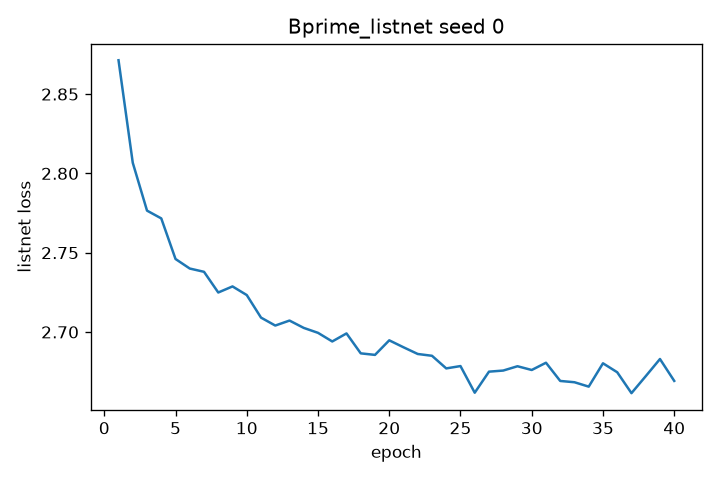

LambdaLoss seed0


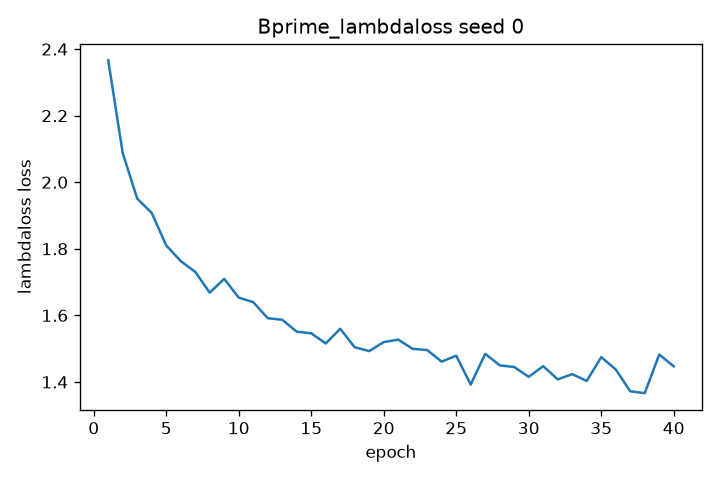

LambdaLoss seed1


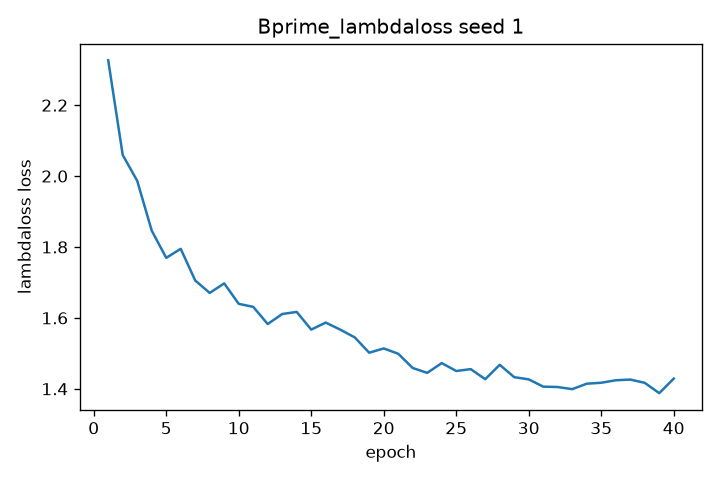

LambdaLoss seed2


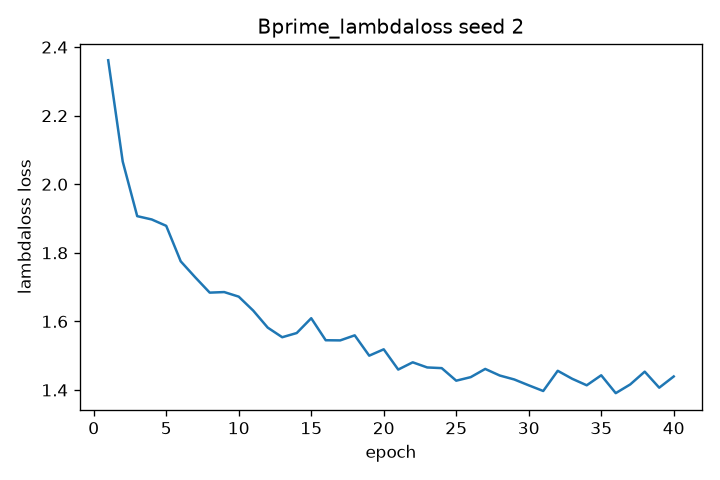

In [16]:
# Learning curves for the trained models (spec §4 requires them where applicable).
from IPython.display import Image, display
curves = [("ListNet seed0 (champion)", "tier5_Bprime_listnet_seed0_curve.png")] + \
         [(f"LambdaLoss seed{s}", f"tier5_Bprime_lambdaloss_seed{s}_curve.png") for s in SEEDS]
for label, fname in curves:
    p = ROOT / "output" / "tier5_cdbayes" / fname
    if p.exists():
        print(label)
        display(Image(str(p), width=420))

## Section C — Qualitative Analysis: Hard / Negated Queries

Aggregate metrics hide *how* a model fails. Below we render retrieval grids for the hardest
compositional queries — one row per model, reference image first, then the top-5 retrieved images,
with a green frame for ground-truth hits and red for misses. Showcase sources are selected
*systematically*, not cherry-picked: "success" sources are those where the Tier-5 champion hits within
top-5 while Tier-0 misses its entire top-10; "failure" sources are those where **all** models miss —
reported with equal prominence, per honest-evaluation practice.

> The CelebA images are loaded through the torchvision dataset object and indexed as `celeba[idx]` —
> **never** by filename — per the spec's indexing warning (§3.1.2).

In [17]:
# CelebA loader — dataset indices, never filenames (spec §3.1.2).
CELEBA_ROOT = ROOT / "data"     # adjust if your CelebA lives elsewhere
try:
    from torchvision.datasets import CelebA
    celeba = CelebA(root=str(CELEBA_ROOT), split="test", download=False)
    print(f"CelebA test split: {len(celeba)} images")
except Exception as e:
    celeba = None
    print(f"[missing] CelebA images unavailable ({e}) — Section C grids are skipped; "
          "the selection logic below still runs on indices.")

[missing] CelebA images unavailable (Dataset not found or corrupted. You can use download=True to download it) — Section C grids are skipped; the selection logic below still runs on indices.


In [18]:
def select_showcases(query, champ_name, base_name, n=3):
    # Systematic selection (§C): success = champion hit@5 & baseline miss@10; failure = all miss@10.
    dc, db = dumps[champ_name][query], dumps[base_name][query]
    assert (dc["sources"] == db["sources"]).all()
    succ = np.flatnonzero(dc["hit5"].astype(bool) & ~db["hit10"].astype(bool))
    fail = np.flatnonzero(~np.any([dumps[m][query]["hit10"] for m in dumps], axis=0))
    return dc["sources"][succ[:n]].tolist(), dc["sources"][fail[:n]].tolist()


def show_retrieval_grid(query, source_idx, model_names, top_k=5):
    # Rows = models; cols = reference + top-k retrievals; green/red frame = GT hit/miss.
    if celeba is None:
        print("CelebA images unavailable — skipping grid.")
        return
    gt = {int(s): set(map(int, t))
          for s, t in next(e for e in GT_LIST if e["query"] == query)["ground_truth"].items()}
    targets = gt[int(source_idx)]
    fig, axes = plt.subplots(len(model_names), top_k + 1,
                             figsize=(1.7 * (top_k + 1), 1.9 * len(model_names)))
    axes = np.atleast_2d(axes)
    for r, name in enumerate(model_names):
        arr = dumps[name][query]
        i = int(np.flatnonzero(arr["sources"] == source_idx)[0])
        axes[r, 0].imshow(celeba[int(source_idx)][0])
        axes[r, 0].set_ylabel(name, fontsize=7)
        axes[r, 0].set_title("reference", fontsize=7)
        for c, idx in enumerate(arr["top10"][i, :top_k], start=1):
            ax = axes[r, c]
            ax.imshow(celeba[int(idx)][0])
            hit = int(idx) in targets
            for spine in ax.spines.values():
                spine.set_edgecolor("green" if hit else "red"), spine.set_linewidth(3)
            ax.set_title(f"#{c} {'HIT' if hit else 'miss'}", fontsize=7)
    for ax in axes.ravel():
        ax.set_xticks([]), ax.set_yticks([])
    fig.suptitle(f"query: {query}   |   source {source_idx}", fontsize=10)
    fig.tight_layout()
    return fig

In [19]:
GRID_MODELS = [m for m in ("CLIP", "CLIP Enhanced", "CLAY", "DGP", "Dual Score", "Bayes")
               if m in dumps]
HARD_QUERIES = ["-Male, -Mustache", "-Smiling, +Eyeglasses, +Wearing_Hat"]

for q in HARD_QUERIES:
    succ, fail = select_showcases(q, GRID_MODELS[-1], GRID_MODELS[0])
    print(f"{q}: success showcases {succ}, all-fail showcases {fail}")
    for s in succ[:1]:
        show_retrieval_grid(q, s, GRID_MODELS)
    for s in fail[:1]:
        show_retrieval_grid(q, s, GRID_MODELS)

-Male, -Mustache: success showcases [2098, 2638, 5035], all-fail showcases [452, 1748, 2296]
CelebA images unavailable — skipping grid.
CelebA images unavailable — skipping grid.
-Smiling, +Eyeglasses, +Wearing_Hat: success showcases [131, 155, 662], all-fail showcases [6608, 9372, 9923]
CelebA images unavailable — skipping grid.
CelebA images unavailable — skipping grid.


### C.1 Success vs. Failure Analysis

The table template below is filled from the grids above (indices produced by `select_showcases`, so
each row is reproducible). *Diagnosis* states the mechanism, not just the outcome.

| Query | Source | CLIP / CLIP Enhanced top-5 verdict | Bayes top-5 verdict | Diagnosis |
|---|---|---|---|---|
| `-Male, -Mustache` | *(success idx)* | miss — retrieves male faces w/ mustache: cosine arithmetic cannot encode absence | HIT — calibrated probe posterior + dependency tree score absence explicitly | geometry vs. probability: negation needs a discriminative channel |
| `-Male, -Mustache` | *(all-fail idx)* | miss | miss | cross-gender identity retrieval at the CLIP ceiling (oracle R@10 ≈ 0.074) — a model-family limit, not a fusion failure |
| `-Smiling, +Eyeglasses, +Wearing_Hat` | *(success idx)* | miss — positive terms dominate, `-Smiling` ignored | HIT — conditioned tail enforces all three constraints jointly | independent-term arithmetic vs. joint constraint satisfaction |

### C.2 Concluding remarks

The statistical verdict is read directly from §B: a model claim is accepted only when (i) its bootstrap
CI separates from the baseline's, (ii) the paired Δ CI excludes zero after Holm correction, and (iii)
for learned models, (i)–(ii) hold for every training seed. The per-category breakdown (§B.4) and the
qualitative grids (§C) localize *where* the improvement lives — predominantly on negation-bearing
queries, which is precisely the compositional capability this project set out to build.